# **ResNet-18 on CIFAR-10**
Same data and training recipe as `assignment_2.ipynb` (Run 2: 92.85%), with the plain CNN replaced
by a ResNet-18 to reach 95%+. Additions: mixed precision (bf16), flip test-time augmentation.

Run 3 (60 epochs): 95.74% with flip TTA. Run 4 (this version) adds AutoAugment, CutMix and 200 epochs to reduce overfitting (Run 3 reached 98.6% train vs 95.7% test accuracy).

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cudnn.benchmark = True       # pick the fastest conv algorithms for fixed 32x32 inputs
print(device, torch.cuda.get_device_name(0) if device == "cuda" else "")

c:\Users\Admin\Documents\GitHub\DL-Assignment2-CNN-CIFAR\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


cuda NVIDIA GeForce RTX 4080 SUPER


# **Data and Augmentation**

In [2]:
MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4, padding_mode="reflect"),
    transforms.RandomHorizontalFlip(),
    transforms.AutoAugment(transforms.AutoAugmentPolicy.CIFAR10),   # learned CIFAR-10 augmentation policy
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
    transforms.RandomErasing(p=0.25),
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_dataset = datasets.CIFAR10(root="../dataset", train=True, download=True, transform=train_transform)
test_dataset = datasets.CIFAR10(root="../dataset", train=False, download=True, transform=test_transform)

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=8,
    pin_memory=True,
    persistent_workers=True
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=8,
    pin_memory=True,
    persistent_workers=True
)
classes = train_dataset.classes
print(f"Train length: {len(train_dataset)}\nTest length: {len(test_dataset)}\nClasses: {classes}")

Train length: 50000
Test length: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


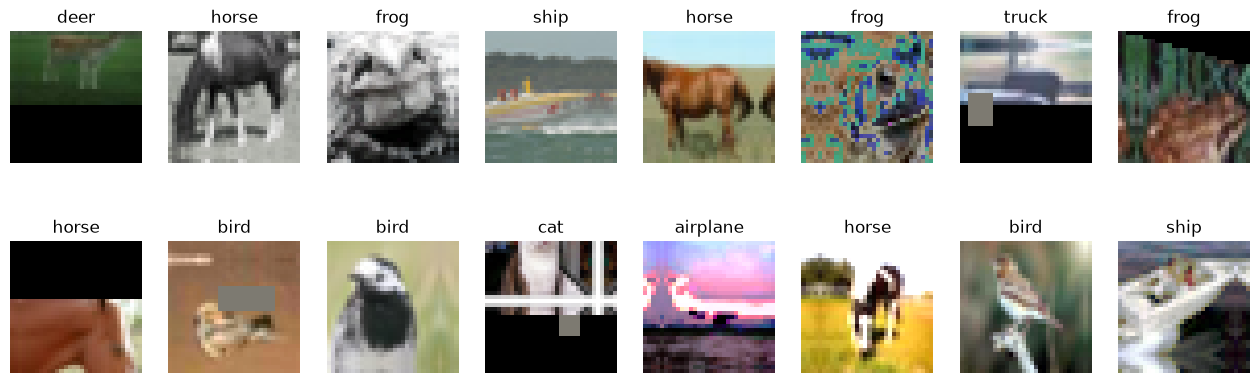

In [3]:
# preview augmented training images (un-normalized for display)
images, labels = next(iter(train_loader))
mean, std = torch.tensor(MEAN).view(3, 1, 1), torch.tensor(STD).view(3, 1, 1)
fig, axes = plt.subplots(2, 8, figsize=(16, 5))
for img, label, ax in zip(images, labels, axes.flat):
    ax.imshow((img * std + mean).clamp(0, 1).permute(1, 2, 0))
    ax.set_title(classes[label])
    ax.axis("off")
plt.show()

# **Define The Network: ResNet-18**

In [4]:
class BasicBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.shortcut = nn.Sequential()
        if stride != 1 or in_ch != out_ch:              # match shape for the skip connection
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, stride, bias=False),
                nn.BatchNorm2d(out_ch))

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x))           # skip connection

class ResNet18(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.stem = nn.Sequential(                      #32x32x64
            nn.Conv2d(3, 64, 3, 1, 1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU())
        self.layer1 = self._make_layer(64, 64, 1)       #32x32x64
        self.layer2 = self._make_layer(64, 128, 2)      #16x16x128
        self.layer3 = self._make_layer(128, 256, 2)     #8x8x256
        self.layer4 = self._make_layer(256, 512, 2)     #4x4x512
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),                    #1x1x512
            nn.Flatten(),
            nn.Linear(512, num_classes))

    def _make_layer(self, in_ch, out_ch, stride):
        return nn.Sequential(BasicBlock(in_ch, out_ch, stride),
                             BasicBlock(out_ch, out_ch, 1))

    def forward(self, x):
        x = self.stem(x)
        x = self.layer4(self.layer3(self.layer2(self.layer1(x))))
        return self.classifier(x)

print(f"Parameters: {sum(p.numel() for p in ResNet18().parameters()) / 1e6:.2f}M")

Parameters: 11.17M


# **Training and Evaluation**

In [5]:
from torchvision.transforms import v2

AMP_DTYPE = torch.bfloat16      # RTX 30-series or newer; use torch.float16 + GradScaler on older GPUs
cutmix = v2.CutMix(num_classes=10)
CUTMIX_PROB = 0.5

def train_one_epoch(model, loader, optimizer, criterion, scheduler=None):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, labels in tqdm(loader, desc="Training", leave=False):
        images = images.to(device, non_blocking=True).to(memory_format=torch.channels_last)
        labels = labels.to(device, non_blocking=True)
        if torch.rand(1).item() < CUTMIX_PROB:
            images, labels = cutmix(images, labels)     # paste patches between images, labels become soft (N, 10)
        optimizer.zero_grad()
        with torch.autocast(device_type="cuda", dtype=AMP_DTYPE):
            outputs = model(images)
            loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        if scheduler is not None:
            scheduler.step()
        total_loss += loss.item() * images.size(0)
        hard_labels = labels.argmax(1) if labels.ndim == 2 else labels
        correct += (outputs.argmax(1) == hard_labels).sum().item()
        total += labels.size(0)
    return total_loss / total, correct / total

def evaluate(model, loader, criterion, tta=True):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True).to(memory_format=torch.channels_last)
            labels = labels.to(device, non_blocking=True)
            with torch.autocast(device_type="cuda", dtype=AMP_DTYPE):
                outputs = model(images)
                if tta:                                 # average with horizontally flipped images
                    outputs = (outputs + model(torch.flip(images, dims=[3]))) / 2
                loss = criterion(outputs, labels)
            total_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, correct / total

def fit(model, train_loader, test_loader, epochs, optimizer, criterion, scheduler):
    history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
    for epoch in range(epochs):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, criterion, scheduler)
        te_loss, te_acc = evaluate(model, test_loader, criterion)
        history["train_loss"].append(tr_loss); history["train_acc"].append(tr_acc)
        history["test_loss"].append(te_loss);  history["test_acc"].append(te_acc)
        print(f"Epoch {epoch+1}/{epochs} | train loss {tr_loss:.4f} | train acc {tr_acc:.4f} | "
              f"test loss {te_loss:.4f} | test acc {te_acc:.4f}")
    return history

def plot_history(history, title=""):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(epochs, history["train_loss"], label="train loss")
    ax1.plot(epochs, history["test_loss"], label="test loss")
    ax1.set_xlabel("epoch"); ax1.set_ylabel("loss"); ax1.legend()
    ax2.plot(epochs, history["train_acc"], label="train acc")
    ax2.plot(epochs, history["test_acc"], label="test acc")
    ax2.set_xlabel("epoch"); ax2.set_ylabel("accuracy"); ax2.legend()
    fig.suptitle(title)
    plt.show()

# **Train**

Epoch 1/200 | train loss 1.9967 | train acc 0.3208 | test loss 1.4246 | test acc 0.5741


Epoch 2/200 | train loss 1.7546 | train acc 0.4628 | test loss 1.2839 | test acc 0.6520


Epoch 3/200 | train loss 1.6261 | train acc 0.5342 | test loss 1.1259 | test acc 0.7332


Epoch 4/200 | train loss 1.5577 | train acc 0.5735 | test loss 1.1233 | test acc 0.7264


Epoch 5/200 | train loss 1.5255 | train acc 0.5897 | test loss 1.0255 | test acc 0.7747


Epoch 6/200 | train loss 1.4728 | train acc 0.6165 | test loss 0.9900 | test acc 0.7859


... (190 outputs left out)

Epoch 197/200 | train loss 0.8945 | train acc 0.8848 | test loss 0.5982 | test acc 0.9691


Epoch 198/200 | train loss 0.9314 | train acc 0.8712 | test loss 0.6198 | test acc 0.9686


Epoch 199/200 | train loss 0.9295 | train acc 0.8789 | test loss 0.5868 | test acc 0.9693


Epoch 200/200 | train loss 0.9452 | train acc 0.8702 | test loss 0.6032 | test acc 0.9683


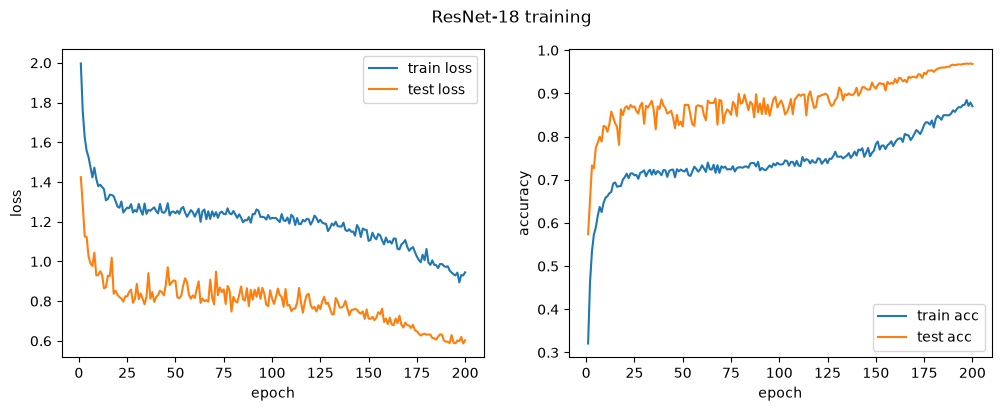

In [6]:
EPOCHS = 200
model = ResNet18().to(device).to(memory_format=torch.channels_last)
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.SGD(model.parameters(), lr=0.1, momentum=0.9, nesterov=True, weight_decay=5e-4)
scheduler = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=0.1, epochs=EPOCHS, steps_per_epoch=len(train_loader))
history = fit(model, train_loader, test_loader, EPOCHS, optimizer, criterion, scheduler)
plot_history(history, "ResNet-18 training")
torch.save(model.state_dict(), "resnet18_cifar10.pth")

# **Final Results**

In [7]:
_, acc_plain = evaluate(model, test_loader, criterion, tta=False)
_, acc_tta = evaluate(model, test_loader, criterion, tta=True)
print(f"Test accuracy without TTA: {acc_plain:.4f}")
print(f"Test accuracy with flip TTA: {acc_tta:.4f}")

# per-class accuracy
model.eval()
class_correct, class_total = torch.zeros(10), torch.zeros(10)
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device).to(memory_format=torch.channels_last)
        with torch.autocast(device_type="cuda", dtype=AMP_DTYPE):
            outputs = model(images) + model(torch.flip(images, dims=[3]))
        preds = outputs.argmax(1).cpu()
        for c in range(10):
            mask = labels == c
            class_correct[c] += (preds[mask] == c).sum()
            class_total[c] += mask.sum()
for c, name in enumerate(classes):
    print(f"{name:>10}: {class_correct[c] / class_total[c]:.4f}")

Test accuracy without TTA: 0.9653
Test accuracy with flip TTA: 0.9683
  airplane: 0.9700
automobile: 0.9850
      bird: 0.9610
       cat: 0.9170
      deer: 0.9710
       dog: 0.9470
      frog: 0.9880
     horse: 0.9830
      ship: 0.9850
     truck: 0.9760
